<a href="https://colab.research.google.com/github/ayyboddu/MultiAsset-Risk-Regime-Engine/blob/main/MultiAsset_Risk_Regime_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance arch

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf
from arch import arch_model
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
print("Environment ready.")


Environment ready.


In [5]:
# 1. Define our 8 global macro assets (Yahoo Finance ticker : Plain-English Name)
tickers = {
    'SPY': 'US Equities (S&P 500)',
    'VGK': 'European Equities (FTSE Europe)',
    'EWJ': 'Japanese Equities (MSCI Japan)',
    'IEF': 'US 7-10Y Treasury Bonds',
    'TLT': 'US 20Y+ Sovereign Bonds',
    'FXE': 'EUR/USD Exchange Rate',
    'FXY': 'JPY/USD Exchange Rate',
    'GLD': 'Gold (Safe-Haven Commodity)',
    'USO': 'WTI Crude Oil'
}

raw_data = yf.download(list(tickers.keys()), start='2015-01-01', progress=False)

raw_data.columns
raw_data.head(2)

Price           Close                                                \
Ticker            EWJ         FXE        FXY         GLD        IEF   
Date                                                                  
2015-01-02  36.173817  111.884872  80.720001  114.080002  81.186844   
2015-01-05  35.756187  111.260147  81.309998  115.800003  81.682236   

Price                                                          High  ...  \
Ticker             SPY        TLT         USO        VGK        EWJ  ...   
Date                                                                 ...   
2015-01-02  169.267487  91.182693  159.119995  35.678574  36.527201  ...   
2015-01-05  166.210571  92.615044  150.320007  34.638458  35.981068  ...   

Price            Open   Volume                                               \
Ticker            VGK      EWJ     FXE     FXY      GLD      IEF        SPY   
Date                                                                          
2015-01-02  35.918075  7191725  497700  175100  7109600  2028600  121465900   
2015-01-05  35.069558  8672550  698700  244300  8177400  1521700  169632600   

Price                                  
Ticker          TLT      USO      VGK  
Date                                   
2015-01-02  9432000  2638313  3700800  
2015-01-05  9789500  3937438  6173600  

[2 rows x 45 columns]

In [6]:
prices = raw_data['Close'].rename(columns=tickers).dropna()
print(prices.shape)
prices.head()


(2991, 9)


Ticker,Japanese Equities (MSCI Japan),EUR/USD Exchange Rate,JPY/USD Exchange Rate,Gold (Safe-Haven Commodity),US 7-10Y Treasury Bonds,US Equities (S&P 500),US 20Y+ Sovereign Bonds,WTI Crude Oil,European Equities (FTSE Europe)
Date,,,,,,,,,
2015-01-02,36.173817,111.884872,80.720001,114.080002,81.186844,169.267487,91.182693,159.119995,35.678574
2015-01-05,35.756187,111.260147,81.309998,115.800003,81.682236,166.210571,92.615044,150.320007,34.638458
2015-01-06,35.177910,110.900475,82.110001,117.120003,82.230949,164.645081,94.283684,144.399994,34.248425
2015-01-07,35.691925,110.266251,81.660004,116.430000,82.215683,166.696732,94.097527,146.960007,34.604259
2015-01-08,36.141682,109.878128,81.320000,115.940002,81.880318,169.654785,92.851349,148.399994,35.103783


In [8]:
#compute daily log returns
log_returns = np.log(prices/prices.shift(1)).dropna()

#risk & fat-tail summary table
summary_stats = pd.DataFrame({
    'Annual Return (%)': log_returns.mean()*252*100,
    'Annual Volatility (%)': log_returns.std() * np.sqrt(252) * 100,
    'Skewness': log_returns.skew(),
    'Excess Kurtosis': log_returns.kurtosis()
})

print("--- Global Multi-Asset Risk & Fat-Tail Summary (2015-Present) ---")
display(summary_stats.round(2))


--- Global Multi-Asset Risk & Fat-Tail Summary (2015-Present) ---


,Annual Return (%),Annual Volatility (%),Skewness,Excess Kurtosis
Ticker,,,,
Japanese Equities (MSCI Japan),7.39,17.97,-0.46,6.10
EUR/USD Exchange Rate,-0.89,7.82,0.13,2.23
JPY/USD Exchange Rate,-2.83,9.31,0.61,4.67
Gold (Safe-Haven Commodity),9.03,16.50,-0.59,6.97
US 7-10Y Treasury Bonds,1.02,6.54,0.12,2.94
US Equities (S&P 500),12.23,17.67,-0.56,14.18
US 20Y+ Sovereign Bonds,-0.93,14.72,-0.00,4.51
WTI Crude Oil,-1.49,40.62,-1.25,14.91
European Equities (FTSE Europe),7.27,18.87,-1.22,15.63


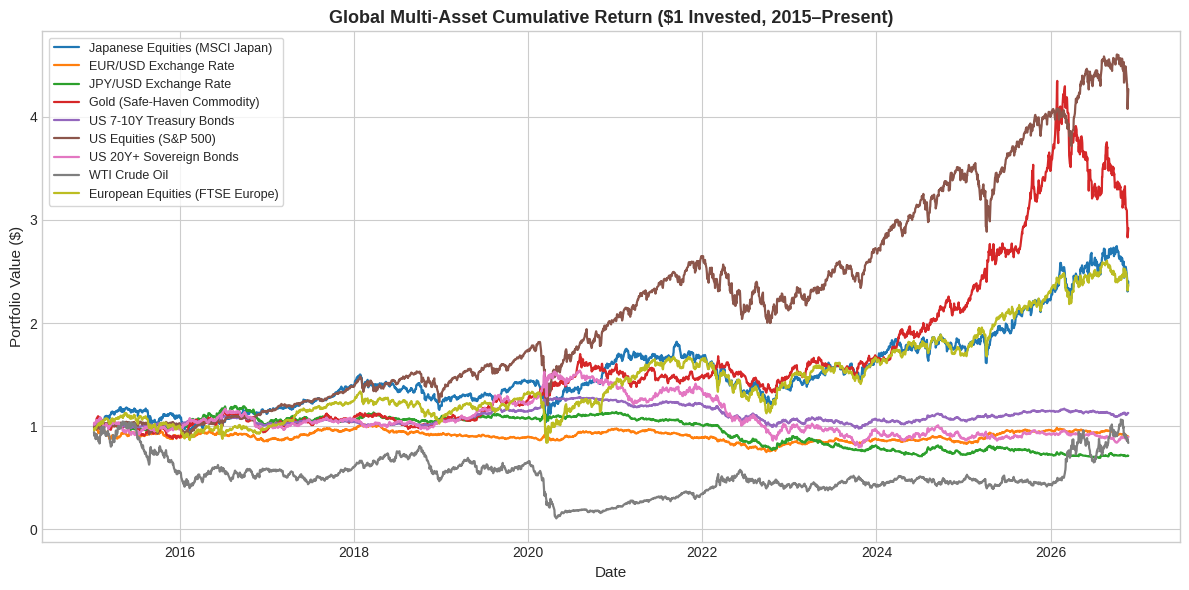

In [9]:
#Plot cumulative growth of $1 invested in each asset
cumulative_growth = np.exp(log_returns.cumsum())

plt.figure(figsize=(12,6))
for col in cumulative_growth.columns:
  plt.plot(cumulative_growth.index,cumulative_growth[col],label = col,linewidth=1.6)

plt.title('Global Multi-Asset Cumulative Return ($1 Invested, 2015–Present)', fontsize=13, fontweight='bold')
plt.ylabel('Portfolio Value ($)', fontsize=11)
plt.xlabel('Date', fontsize=11)
plt.legend(loc='upper left', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()